In [2]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [3]:
if DATASET == "Synthetic":
    IMG_SIZE = 28
    NUM_CLASSES = 4
    CLASSES = ['Top-Left', 'Top-Right', 'Bottom-Left', 'Bottom-Right']
elif DATASET == "Small-MNIST":
    IMG_SIZE = 28
    NUM_CLASSES = 4
    CLASSES = list(range(NUM_CLASSES))
elif DATASET == "MNIST":
    IMG_SIZE = 28
    NUM_CLASSES = 10
    CLASSES = list(range(NUM_CLASSES))
else:
    raise ValueError("Unknown dataset.")

BATCH_SIZE = 128
INPUT_DIM = IMG_SIZE * IMG_SIZE

print(f"Dataset: {DATASET} ({INPUT_DIM} → {NUM_CLASSES}) | batch size {BATCH_SIZE}")

Dataset: Synthetic (784 → 4) | batch size 128


In [4]:
# Synthetic data: 2D Gaussian blobs at random positions in 4 quadrants
def get_synthetic_data(n, sz=28):
    images = np.zeros((n, sz, sz), dtype=np.float32)
    labels = np.zeros(n, dtype=np.int64)
    sigma = max(1.0, sz / 12)                # blob scale; fades to ~0 well before the border
    margin = 3 * sigma                       # keep most of the mass inside the frame
    mid = sz / 2
    ys, xs = np.mgrid[0:sz, 0:sz]
    for i in range(n):
        cx = np.random.uniform(margin, sz - margin - 1)
        cy = np.random.uniform(margin, sz - margin - 1)
        images[i] = np.exp(-((xs - cx)**2 + (ys - cy)**2) / (2 * sigma**2)).astype(np.float32)
        labels[i] = (cx >= mid) + 2 * (cy >= mid)
    return torch.from_numpy(images), torch.from_numpy(labels)


if DATASET == "Synthetic":
    x_train, y_train = get_synthetic_data(8000, sz=IMG_SIZE)
    x_test,  y_test  = get_synthetic_data(2000, sz=IMG_SIZE)
    train_dataset = TensorDataset(x_train.view(-1, 1, IMG_SIZE, IMG_SIZE), y_train)
    test_dataset  = TensorDataset(x_test.view(-1, 1, IMG_SIZE, IMG_SIZE),  y_test)
else:
    transform = transforms.Compose([transforms.ToTensor()])
    full_train = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
    full_test  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

    def filter_digits(dataset, digits):
        digit_set = set(digits)
        indices = [i for i, (_, y) in enumerate(dataset) if y in digit_set]
        return Subset(dataset, indices)

    train_dataset = filter_digits(full_train, CLASSES)
    test_dataset  = filter_digits(full_test, CLASSES)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Train set: {len(train_dataset)} samples ({len(train_loader)} batches)")
print(f"Test set:  {len(test_dataset)} samples ({len(test_loader)} batches)")

Train set: 8000 samples (63 batches)
Test set:  2000 samples (16 batches)


In [5]:
def show_reconstructions(model, data_loader, n=10, title="Reconstructions"):
    """Display original images alongside their reconstructions."""
    model.eval()
    with torch.no_grad():
        x, _ = next(iter(data_loader))
        x = x.to(device)[:n]
        recon = model(x)[0]
    fig, axes = plt.subplots(2, n, figsize=(n * 1.5, 3))
    for i in range(n):
        axes[0, i].imshow(x[i].cpu().view(IMG_SIZE, IMG_SIZE), cmap="gray")
        axes[0, i].axis("off")
        axes[1, i].imshow(recon[i].cpu().view(IMG_SIZE, IMG_SIZE), cmap="gray")
        axes[1, i].axis("off")
    axes[0, 0].set_title("$x$", fontsize=10)
    axes[1, 0].set_title(r"$\hat{x}$", fontsize=10)
    fig.suptitle(title, fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()


def show_samples(model, n=10, title="Samples from Prior"):
    """Draw latent vectors from the prior, decode, and display."""
    model.eval()
    with torch.no_grad():
        samples = model.sample(n).cpu()
    fig, axes = plt.subplots(1, n, figsize=(n * 1.5, 1.5))
    for i in range(n):
        axes[i].imshow(samples[i].cpu().view(IMG_SIZE, IMG_SIZE), cmap="gray")
        axes[i].axis("off")
    fig.suptitle(title, fontsize=13, y=1.05)
    plt.tight_layout()
    plt.show()


def plot_losses(loss_dict: dict, title="Training Loss"):
    """Plot one curve per key in loss_dict."""
    plt.figure(figsize=(8, 4))
    for label, values in loss_dict.items():
        plt.plot(values, label=label)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def show_latent_space(model, data_loader, title="Latent Space"):
    """Scatter-plot the first two latent dimensions, coloured by digit class."""
    model.eval()
    zs, ys = [], []
    with torch.no_grad():
        for x, y in data_loader:
            x = x.to(device)
            z = model.encode(x)
            zs.append(z[:, :2].cpu())
            ys.append(y)
    zs = torch.cat(zs)
    ys = torch.cat(ys)
    plt.figure(figsize=(6, 5))
    scatter = plt.scatter(zs[:, 0], zs[:, 1], c=ys, cmap="tab10",
                          s=1, alpha=0.5, vmin=0, vmax=9)
    plt.colorbar(scatter)
    plt.title(title)
    plt.xlabel("$z_1$")
    plt.ylabel("$z_2$")
    plt.tight_layout()
    plt.show()


def discriminator_accuracy(model, data_loader, n_batches=10):
    """
    Estimate discriminator accuracy on held-out real vs. fake latent codes.
    A well-trained AAE should push this towards 50 % (discriminator confused).
    """
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for i, (x, _) in enumerate(data_loader):
            if i >= n_batches:
                break
            x = x.to(device)
            n = x.size(0)
            z_fake = model.encode(x)
            z_real = torch.randn(n, model.latent_dim).to(device)
            # discriminator outputs: >0.5 → predicted real
            pred_real = (model.discriminator(z_real) > 0.5).float()
            pred_fake = (model.discriminator(z_fake) > 0.5).float()
            correct += pred_real.sum().item() + (1 - pred_fake).sum().item()
            total   += 2 * n
    acc = correct / total
    print(f"Discriminator accuracy (real vs. fake): {acc:.4f}  (ideal ≈ 0.50)")
    return acc

def show_latent_traversal(model, dim_to_traverse=0, n_steps=10, z_range=(-3, 3), title="Traversal"):
    model.eval()
    with torch.no_grad():
        z = torch.zeros(n_steps, latent_dim).to(device)
        z[:, dim_to_traverse] = torch.linspace(z_range[0], z_range[1], n_steps)
        samples = model.decoder(z)

    fig, axes = plt.subplots(1, n_steps, figsize=(n_steps * 1.2, 1.5))
    for i in range(n_steps):
        axes[i].imshow(samples[i].cpu().view(IMG_SIZE, IMG_SIZE), cmap="gray")
        axes[i].axis("off")
    fig.suptitle(f"{title} — dim {dim_to_traverse}", fontsize=11, y=1.05)
    plt.tight_layout()
    plt.show()

In [6]:
class Encoder(nn.Module):
    """
    Convolutional encoder. Maps an image x ∈ [0,1]^{1×28×28} to
    a latent code z ∈ ℝ^{latent_dim}

    Architecture:
        Conv(1 → C,   4×4, stride=2, pad=1)  → ReLU   # 28×28 → 14×14
        Conv(C → 2C,  4×4, stride=2, pad=1)  → ReLU   # 14×14 → 7×7
        Flatten → Linear(2C·7·7 → latent_dim)
    """
    def __init__(self, hidden_channels: int, latent_dim: int):
        super().__init__() # inizializzazione della classe padre nn.Module
        
        # prima convoluzione che estrae features spaziali mappando un canale a quelli nascosti
        # usando ReLU come funzione di attivazione non lineare
        self.conv1 = nn.Conv2d(in_channels=1, out_channels = hidden_channels, kernel_size=4, stride = 2, padding = 1)
        self.relu1 = nn.ReLU()
        
        # seconda convoluzione che estrae altre features raddoppiando i canali
        self.conv2 = nn.Conv2d(in_channels = hidden_channels, out_channels = hidden_channels *2, kernel_size = 4, stride=2, padding = 1)
        self.relu2 = nn.ReLU()
        
        # appiattimento del tensore 3D delle features estratte in un vettore 1D per il livello lineare
        self.flatten = nn.Flatten()
        
        # trasformazione linare finale (fully connected) in cui il vettore appiattito
        # viene proiettato nello spazio latente di dimensione 'latent_dim'
        self.fc = nn.Linear(in_features = (hidden_channels*2) * 7 *7, out_features = latent_dim)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # applicazione in sequenza dei layer definiti precedenti per mappare x in z
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.flatten(x)
        z = self.fc(x)
        
        return z

In [7]:
class Decoder(nn.Module):
    """
    Symmetric convolutional decoder.
    Maps z ∈ ℝ^{latent_dim} back to an image x̂ ∈ [0,1]^{1×28×28}.

    Architecture:
        Linear(latent_dim → 2C·7·7) → reshape (2C, 7, 7)
        ConvTranspose(2C → C,  4×4, stride=2, pad=1)  → ReLU   # 7×7  → 14×14
        ConvTranspose(C  → 1,  4×4, stride=2, pad=1)  → Sigmoid # 14×14 → 28×28
    """
    def __init__(self, hidden_channels: int, latent_dim: int):
        super().__init__()
        
        # memorizzazione dei canali nascosti per ricostruire il tensore 3D (unflattening)
        self.hidden_channels = hidden_channels
        
        # trasformazione lineare in cui il z ( attualmente latente) viene espanso
        # in un vettore piatto dimensionato per il volume 3D (2C x 7 x7)
        self.fc = nn.Linear(in_features= latent_dim, out_features=(hidden_channels*2) * 7 *7)
        
        # prima convoluzione trasposta usando come funzione di attivazione non lineare la ReLU
        # la dimensione spaziale viene raddoppiata i canali vengono dimezzati
        self.conv_t1 = nn.ConvTranspose2d(in_channels = hidden_channels*2, out_channels = hidden_channels, kernel_size=4, stride = 2, padding=1)
        self.relu1 = nn.ReLU()
        
        # seconda convoluzione trasposta in cui la dimensione viene raddoppiata ulteriormente e si ritorna ad 1 canale
        self.conv_t2 = nn.ConvTranspose2d(in_channels = hidden_channels, out_channels=1, kernel_size=4, stride=2, padding=1)
        
        # attivazione finale usando la funzione Sigmoide 
        self.sigmoid = nn.Sigmoid()

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        # applicazione sequenziale dei layers che permettono di ricostruire x̂ da z
        x = self.fc(z)
        # unflattening
        # -1 calcola la dimensione della batch size per essere versatile su tutti i dataset
        x = x.view(-1, self.hidden_channels*2, 7, 7)
        x = self.conv_t1(x)
        x = self.relu1(x)
        x = self.conv_t2(x) 
        x_hat = self.sigmoid(x)
        
        return x_hat

In [8]:
class Discriminator(nn.Module):
    """
    MLP discriminator.

    Takes a latent vector z ∈ ℝ^{latent_dim} and
    outputs a scalar probability D(z) ∈ (0, 1).

    Hint: use a two-layer MLP with ReLU activations and Sigmoid output.
    """
    def __init__(self, latent_dim: int, hidden_dim: int = 512):
        super().__init__()
        
        # primo livello lineare in cui le dimensioni latenti vengono proiettate in uno spazio a dimensioni maggiori
        self.fc1 = nn.Linear(in_features=latent_dim, out_features = hidden_dim)
        self.relu = nn.ReLU()
        # secondo livello lineare in cui le features estratte vengono compresse in un'unica feature
        self.fc2 = nn.Linear(in_features=hidden_dim, out_features=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        # applicazione sequenziale a z dei layers 
        z = self.fc1(z)
        z = self.relu(z)
        z = self.fc2(z)
        probability = self.sigmoid(z)
        
        return probability

In [9]:
class AdversarialAutoencoder(nn.Module):
    """
    Wrapper that composes Encoder, Decoder, and Discriminator.
    """
    def __init__(
        self,
        hidden_channels: int,
        latent_dim: int,
        disc_hidden_dim: int = 512,
    ):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = Encoder(hidden_channels, latent_dim)
        self.decoder = Decoder(hidden_channels, latent_dim)
        self.discriminator = Discriminator(latent_dim, disc_hidden_dim)

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        # comprime l'immagine di input x nel vettore latente z tramite l'encoder
        return self.encoder(x)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        # ricostruisce l'immagine a partire dal vettore latente z tramite il decoder
        return self.decoder(z)

    def forward(self, x: torch.Tensor):
        # applicazione sequenziale che prevede l'estrazione di z latente
        # da cui si ricostruisce x̂
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat, z

    def sample(self, n: int) -> torch.Tensor:
        # prima di generare immagini si recupera il device su cui si trova il modello
        # per creare z nello stesso spazio di memoria
        device = next(self.parameters()).device
        # campionamento di n vettori di rumore da una distribuzione (quella che si trova nello spazio latente) normale usando randn 
        z = torch.randn(n, self.latent_dim, device=device)
        # il rumore appena generato viene decodificato per generare nuove immagini
        return self.decode(z)

    def reconstruction_loss(self, recon: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
        """Hint: use the mean reduction."""
        # la loss è la differenza tra i pixel originali e quelli ricostruiti
        return F.binary_cross_entropy(recon, x, reduction='mean')

    def adversarial_losses(
        self,
        z_real: torch.Tensor,
        z_fake: torch.Tensor,
    ):
        """
        Hints:
            - disc_loss : L_D = -E[log D(z_real)] - E[log(1 - D(z_fake))]
            - gen_loss  : L_G = -E[log D(z_fake)]
        """
        # il discriminatore valuta i vettori reali e quelli fake assegnando
        # a ciascuno una probabilità di essere vero
        d_real = self.discriminator(z_real)
        d_fake = self.discriminator(z_fake)
        
        # creazione di vettori pieni di 0 e 1 (etichette target) che rappresentano ciò che 
        # la rete deve imparare (i dati reali devono puntare a 1, mentre quelli fake a 0)
        valid = torch.ones_like(d_real)
        fake = torch.zeros_like(d_fake)
        
        # calcolo della loss del discriminatore
        loss_real = F.binary_cross_entropy(d_real, valid, reduction='mean')
        loss_fake = F.binary_cross_entropy(d_fake, fake, reduction='mean')
        disc_loss = loss_real + loss_fake
        
        # calcolo della loss del generatore
        gen_loss = F.binary_cross_entropy(d_fake, valid, reduction='mean')
        
        return disc_loss, gen_loss

In [10]:
def train_aae(model, train_loader, epochs: int, lr: float, lr_reg: float):
    """
    Train the AAE with the two-phase per-batch loop.

    Hint: you need three optimisers for the three phases
          use lr for the first phase, and lr_reg for the remaining two.

    Return a history dict with keys "Reconstruction", "Discriminator", "Generator",
    each mapping to a list of per-epoch average losses.
    """
    
    # definizione dei tre ottimizzatori necessari con Adam
    opt_ae = torch.optim.Adam(list(model.encoder.parameters()) + list(model.decoder.parameters()), lr=lr)
    opt_disc = torch.optim.Adam(model.discriminator.parameters(), lr=lr_reg)
    opt_gen = torch.optim.Adam(model.encoder.parameters(), lr=lr_reg)
    
    # recupero del device per addestrare il modello nello stesso
    # device in cui si trovano i suoi parametri
    device = next(model.parameters()).device
    
    history = {"Reconstruction": [], "Discriminator": [], "Generator": []}

    for epoch in range(epochs):
        total_recon, total_disc, total_gen = 0.0, 0.0, 0.0

        for x, _ in train_loader:
            # il batch delle immagini viene spostato sul device in cui si trova il modello
            x = x.to(device)
            # si prende il numero di immagini presente nel batch corrente
            batch_size = x.size(0)
            
            # in questa fase l'encoder impara a copiare
            opt_ae.zero_grad() # reset dei gradienti al giro precedente
            x_hat, z = model(x) # x entra nell'encoder ed esce x̂
            recon_loss = model.reconstruction_loss(x_hat, x) # si calcola quanto x̂ è diverso da x
            recon_loss.backward() # calcola come cambiare i pesi per ridurre l'errore
            opt_ae.step() # applicazione dei cambiamenti a encoder e decoder 
            
            # in questa fase il discriminatore impara a distinguere il vero dal falso
            opt_disc.zero_grad()
            # creazione di z_real e z_fake_detached che sono gli esempi di riferimento per il discriminatore
            z_real = torch.randn(batch_size, model.latent_dim, device = device)
            # detach separa i vettori fake dall'encoder per evitare che l'addestramento
            # del discriminatore modifichi quello dell'encoder
            z_fake_detached = model.encode(x).detach()
            # il discriminatore ora valuta entrambi e calcola l'errore
            disc_loss, _ = model.adversarial_losses(z_real, z_fake_detached)
            disc_loss.backward()
            opt_disc.step()
            
            # in questa fase l'encoder impara a generare immagini indistinguibili per 
            # il discriminatore
            opt_gen.zero_grad()
            z_fake = model.encode(x)
            _, gen_loss = model.adversarial_losses(z_real, z_fake)
            gen_loss.backward()
            opt_gen.step()
            
            # You should sum your loss values here!
            total_recon += recon_loss.item() #item() estrae solo il numero puro
            total_disc += disc_loss.item()
            total_gen += gen_loss.item()

        n_batches = len(train_loader)
        history["Reconstruction"].append(total_recon / n_batches)
        history["Discriminator"].append(total_disc  / n_batches)
        history["Generator"].append(total_gen   / n_batches)

        # Keep the logging as it is. It helps us to evaluate your solution.
        print(
            f"Epoch {epoch+1:>3}/{epochs}",
            f"Recon={history['Reconstruction'][-1]:.2f}",
            f"D={history['Discriminator'][-1]:.4f}",
            f"G={history['Generator'][-1]:.4f}"
        )
        if (epoch + 1) % 5 == 0:
            with torch.no_grad():
                show_reconstructions(model, test_loader, title=f"Epoch {epoch+1}")
                show_samples(model, title=f"Epoch {epoch+1}")

    return history

In [ ]:
# Per-dataset hyperparameters
if DATASET == "Synthetic":
    latent_dim, hidden_channels, epochs, lr, lr_reg = 2, 16, 25, 1e-3, 1e-3
elif DATASET == "Small-MNIST":
    latent_dim, hidden_channels, epochs, lr, lr_reg = 2, 32, 30, 3e-4, 1e-3
else:  # MNIST
    latent_dim, hidden_channels, epochs, lr, lr_reg = 2, 32, 30, 3e-4, 5e-4

Epoch   1/25 Recon=0.42 D=1.0461 G=2.3074
Epoch   2/25 Recon=0.15 D=0.3090 G=3.6869
Epoch   3/25 Recon=0.15 D=0.2815 G=2.6131
Epoch   4/25 Recon=0.13 D=1.0933 G=1.2349
Epoch   5/25 Recon=0.12 D=1.2688 G=1.0041


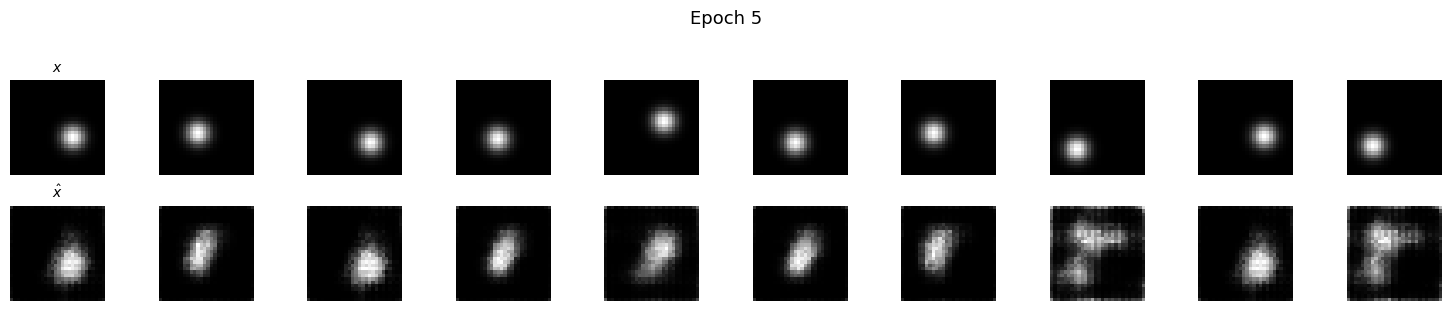

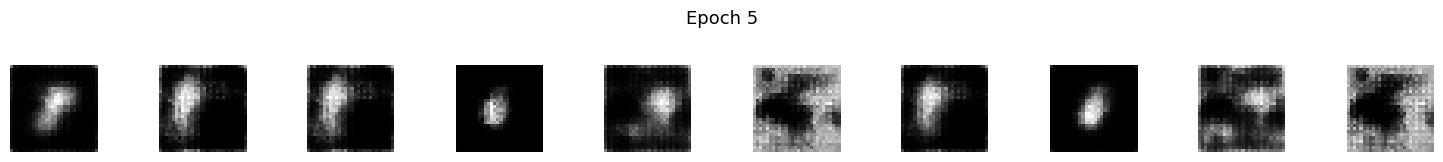

Epoch   6/25 Recon=0.10 D=1.0957 G=1.0254
Epoch   7/25 Recon=0.10 D=1.0828 G=1.0459
Epoch   8/25 Recon=0.09 D=1.1262 G=1.0090
Epoch   9/25 Recon=0.09 D=1.1655 G=0.9532
Epoch  10/25 Recon=0.08 D=1.1775 G=0.9176


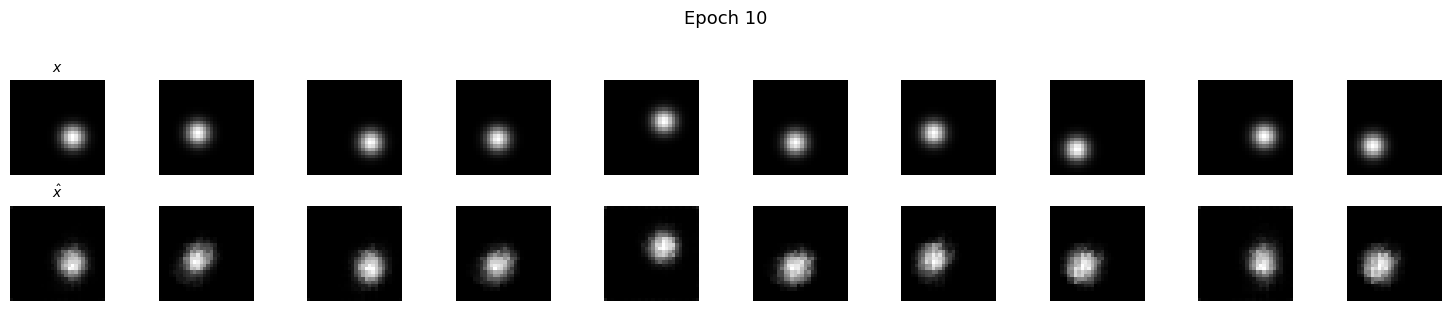

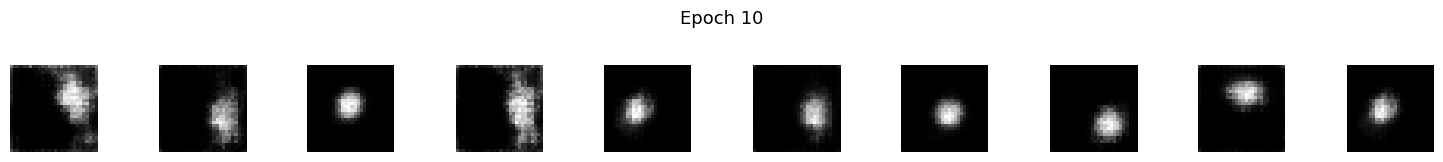

Epoch  11/25 Recon=0.08 D=1.2154 G=0.8680
Epoch  12/25 Recon=0.08 D=1.2351 G=0.8490
Epoch  13/25 Recon=0.08 D=1.2259 G=0.8802
Epoch  14/25 Recon=0.08 D=1.2060 G=0.9416
Epoch  15/25 Recon=0.08 D=1.2700 G=0.8794


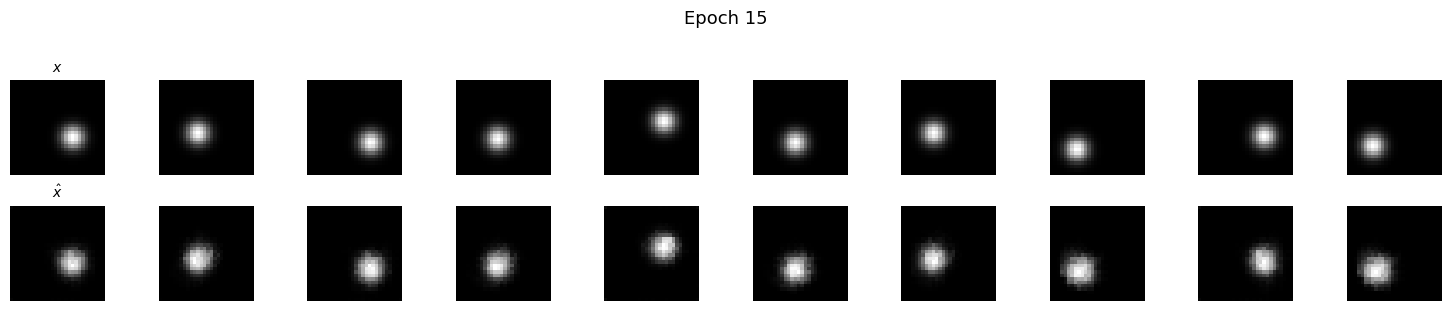

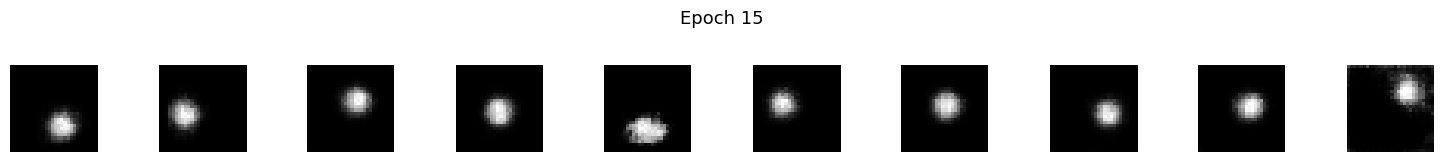

Epoch  16/25 Recon=0.08 D=1.0855 G=1.4160
Epoch  17/25 Recon=0.08 D=1.3670 G=0.7614
Epoch  18/25 Recon=0.07 D=1.3511 G=0.7312
Epoch  19/25 Recon=0.07 D=1.3638 G=0.7137
Epoch  20/25 Recon=0.07 D=1.3624 G=0.7198


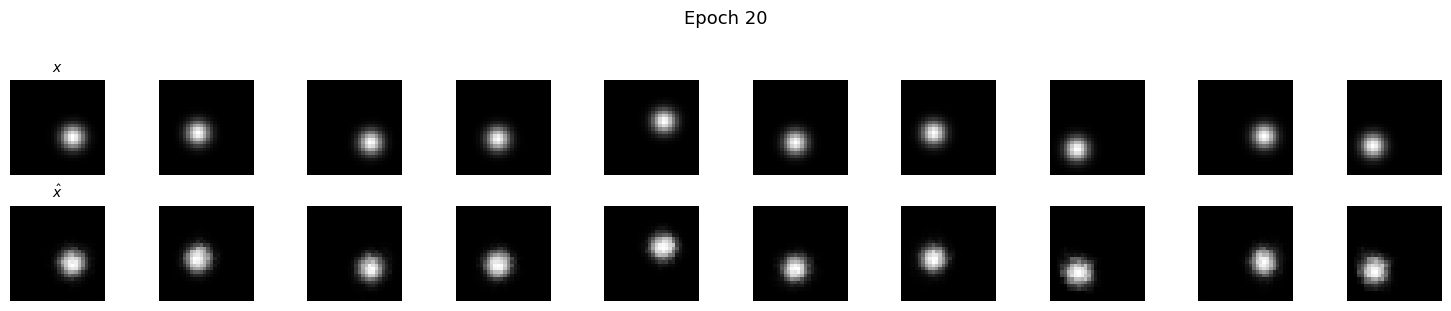

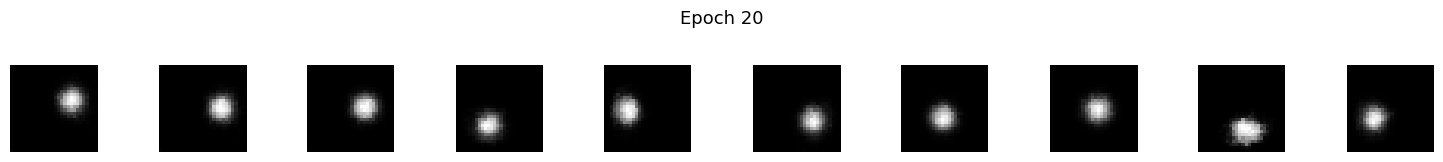

Epoch  21/25 Recon=0.07 D=1.3628 G=0.7162
Epoch  22/25 Recon=0.07 D=1.3167 G=0.8073
Epoch  23/25 Recon=0.08 D=1.2069 G=1.0627
Epoch  24/25 Recon=0.08 D=1.1036 G=1.4271
Epoch  25/25 Recon=0.07 D=1.3300 G=0.7443


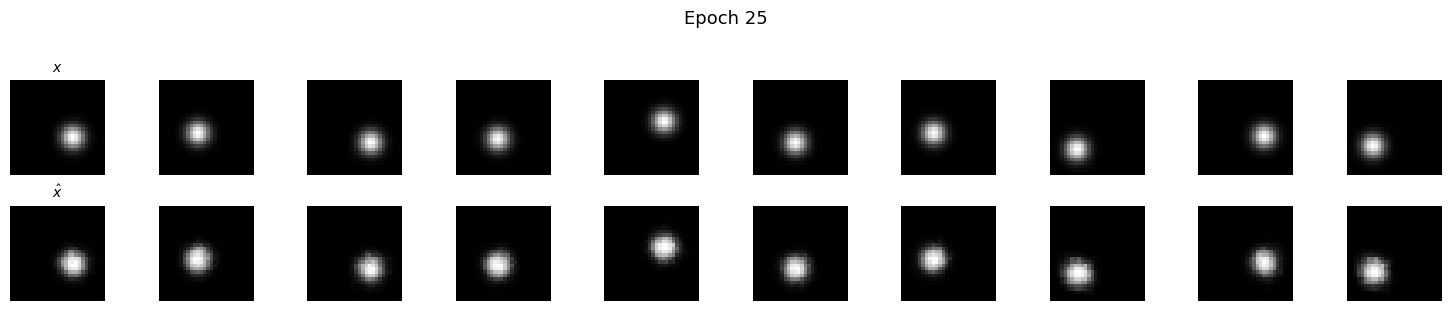

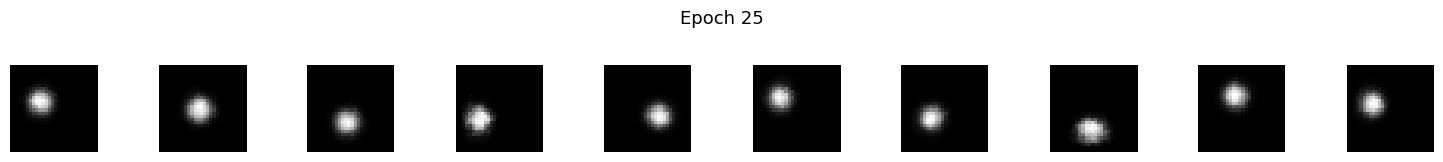

In [12]:
seed_everything(9951)

aae = AdversarialAutoencoder(
    hidden_channels=hidden_channels,
    latent_dim=latent_dim,
).to(device)

history = train_aae(aae, train_loader, epochs=epochs, lr=lr, lr_reg=lr_reg)

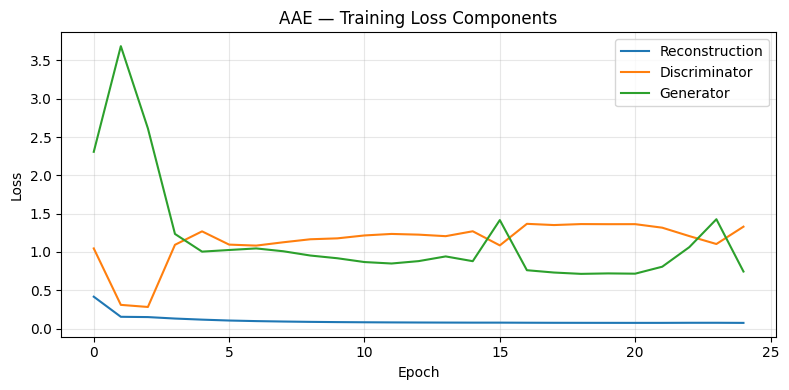

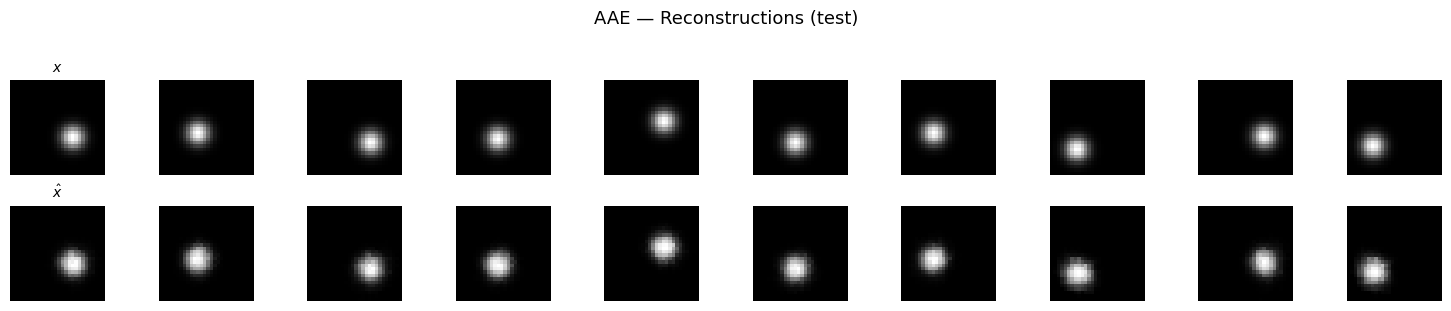

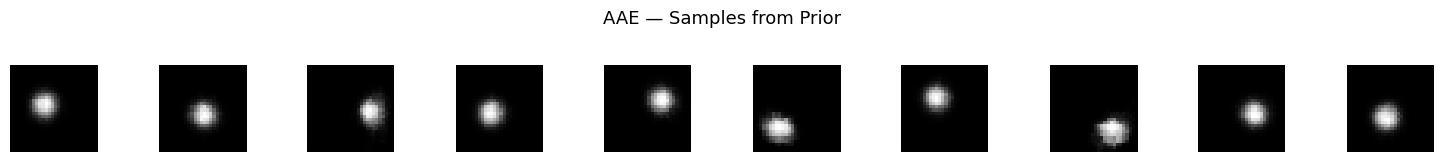

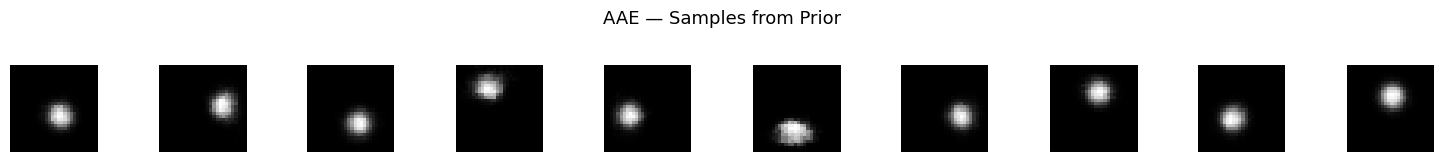

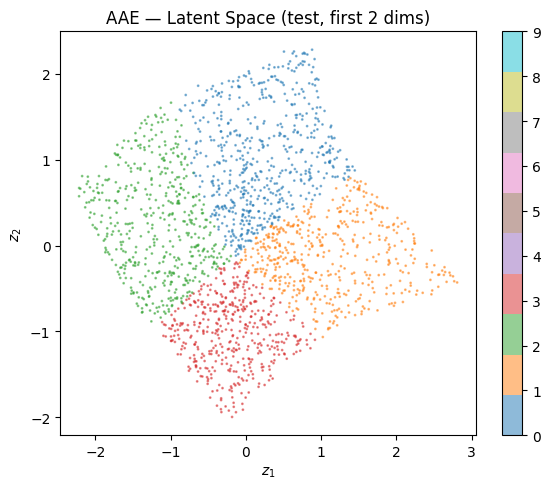

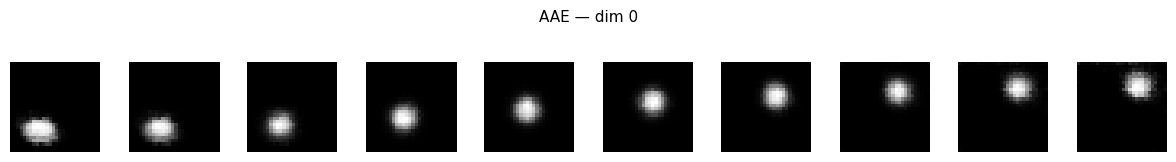

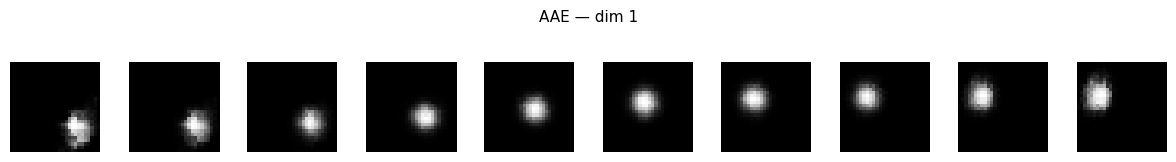

Discriminator accuracy (real vs. fake): 0.5156  (ideal ≈ 0.50)


0.515625

In [13]:
plot_losses(history, "AAE — Training Loss Components")
show_reconstructions(aae, test_loader, title="AAE — Reconstructions (test)")
show_samples(aae, n=10, title="AAE — Samples from Prior")
show_samples(aae, n=10, title="AAE — Samples from Prior")
show_latent_space(aae, test_loader, title="AAE — Latent Space (test, first 2 dims)")
for dim in range(latent_dim):
    show_latent_traversal(aae, dim_to_traverse=dim, title="AAE")
discriminator_accuracy(aae, test_loader)